In [1]:
import pandas as pd
from datetime import datetime


df_jugadores = pd.read_csv("players.csv")
df_valores = pd.read_csv("player_valuations.csv")       
df_partidos_jugados = pd.read_csv("appearances.csv")


df_jugadores['date_of_birth'] = pd.to_datetime(df_jugadores['date_of_birth'])
df_jugadores = df_jugadores.dropna(subset=['date_of_birth'])

current_year = datetime.now().year
df_jugadores['age'] = current_year - df_jugadores['date_of_birth'].dt.year


df_perf = df_partidos_jugados.groupby('player_id').agg(
    total_goals=('goals', 'sum'),
    total_assists=('assists', 'sum')
).reset_index()


df_valores_max = df_valores.groupby('player_id').agg(
    valor_maximo=('market_value_in_eur', 'max')
).reset_index()


df_nuevo1 = df_jugadores[['player_id', 'name', 'position', 'age', 'sub_position']]
df_nuevo1 = df_nuevo1.merge(df_valores_max, on='player_id', how='inner')  
df_nuevo1 = df_nuevo1.merge(df_perf, on='player_id', how='left')


df_nuevo1['total_goals'] = df_nuevo1['total_goals'].fillna(0)
df_nuevo1['total_assists'] = df_nuevo1['total_assists'].fillna(0)


df_nuevo1 = df_nuevo1[df_nuevo1['valor_maximo'] > 0]


posiciones_simplificadas = []

for pos in df_nuevo1['position']:
    if pos == 'Attack':
        posiciones_simplificadas.append('Delantero')
    elif pos == 'Midfield':
        posiciones_simplificadas.append('Mediocampista')
    elif pos == 'Defender':
        posiciones_simplificadas.append('Defensa')
    elif pos == 'Goalkeeper':
        posiciones_simplificadas.append('Portero')
    else:
        posiciones_simplificadas.append('Otros')

df_nuevo1['posicion_general'] = posiciones_simplificadas


df_nuevo1['impacto_ofensivo'] = df_nuevo1['total_goals'] + df_nuevo1['total_assists']
df_nuevo1['eficiencia_por_millon'] = (df_nuevo1['impacto_ofensivo'] / (df_nuevo1['valor_maximo'] / 1e6))

print(df_nuevo1[['name', 'age','position', 'valor_maximo', 'total_goals']].head())




                 name  age    position  valor_maximo  total_goals
0      Miroslav Klose   48      Attack      30000000         48.0
1  Roman Weidenfeller   46  Goalkeeper       8000000          0.0
2    Dimitar Berbatov   45      Attack      34500000         38.0
3               Lúcio   48    Defender      24500000          0.0
4          Tom Starke   45  Goalkeeper       3000000          0.0


In [2]:
resumen_rendimiento = df_nuevo1.groupby('posicion_general').agg(
    valor_promedio=('valor_maximo', lambda x: f"€{int(x.mean()):,}"),
    goles_promedio=('total_goals', lambda x: round(x.mean(), 1)),
    asistencias_promedio=('total_assists', lambda x: round(x.mean(), 1)),
    impacto_ofensivo_promedio=('impacto_ofensivo', lambda x: round(x.mean(), 1))
).reset_index()

print(resumen_rendimiento.to_string(index=False))

posicion_general valor_promedio  goles_promedio  asistencias_promedio  impacto_ofensivo_promedio
         Defensa     €3,118,679             1.8                   2.4                        4.2
       Delantero     €4,158,995             9.4                   5.1                       14.5
   Mediocampista     €3,805,966             4.1                   4.3                        8.3
           Otros       €479,803             2.0                   1.1                        3.1
         Portero     €1,834,982             0.0                   0.1                        0.1


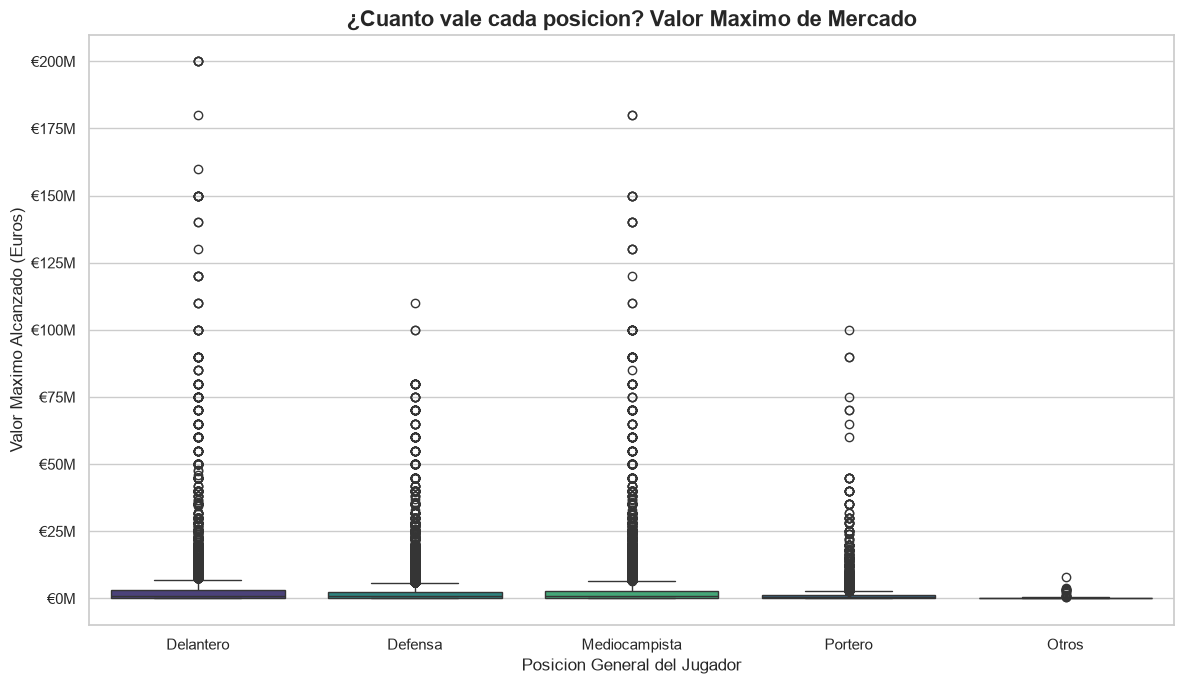

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter


sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 7))


orden_posiciones = df_nuevo1.groupby('posicion_general')['valor_maximo'].median().sort_values(ascending=False).index

sns.boxplot(
    data=df_nuevo1, 
    x='posicion_general', 
    y='valor_maximo', 
    order=orden_posiciones,
    palette="viridis",
    hue='posicion_general',
)


def millones_formato(x, pos):
    return f'€{x * 1e-6:.0f}M'


plt.gca().yaxis.set_major_formatter(FuncFormatter(millones_formato))


plt.title("¿Cuanto vale cada posicion? Valor Maximo de Mercado", fontsize=16, fontweight='bold')
plt.xlabel("Posicion General del Jugador", fontsize=12)
plt.ylabel("Valor Maximo Alcanzado (Euros)", fontsize=12)


plt.tight_layout()

plt.show()

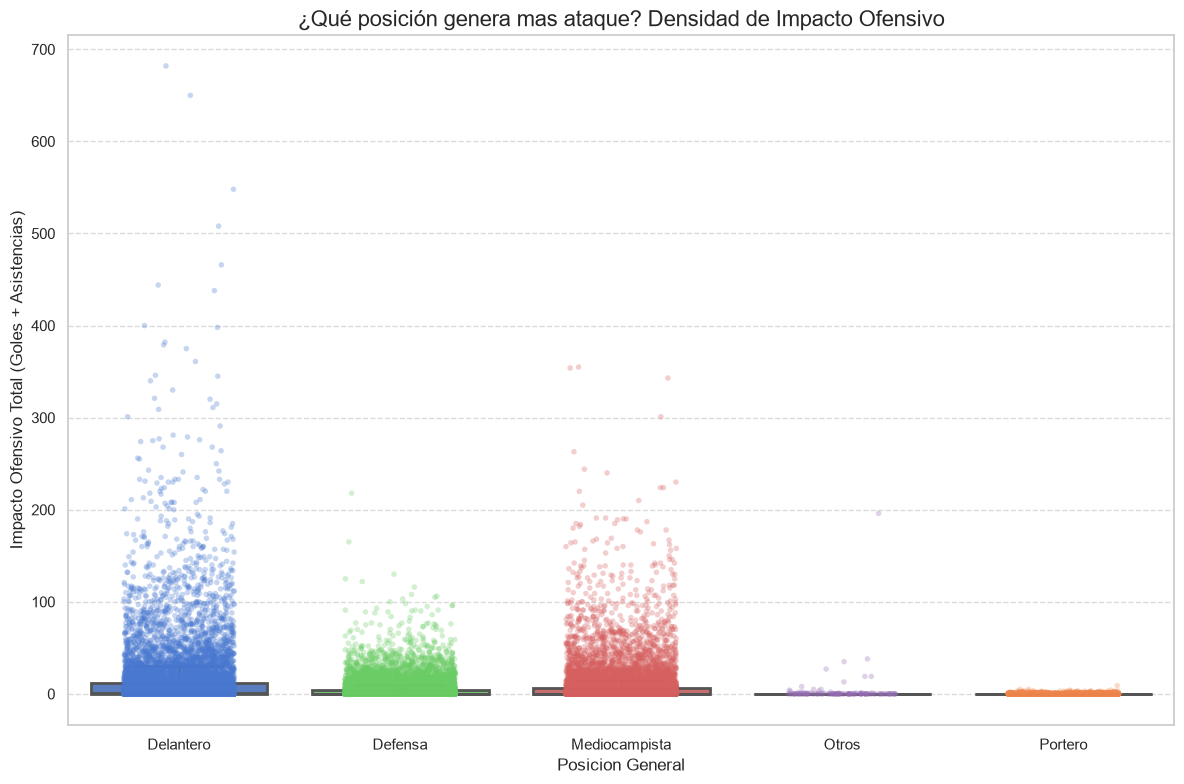

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter


sns.set_theme(style="whitegrid", palette="muted")
fig, ax = plt.subplots(figsize=(12, 8))


orden_posiciones = df_nuevo1.groupby('posicion_general')['impacto_ofensivo'].median().sort_values(ascending=False).index


sns.boxplot(
    data=df_nuevo1, 
    x='posicion_general', 
    y='impacto_ofensivo', 
    order=orden_posiciones,
    hue='posicion_general',
    showfliers=False,     
    linewidth=2,
    ax=ax,
    legend=False
)


sns.stripplot(
    data=df_nuevo1,
    x='posicion_general',
    y='impacto_ofensivo',
    order=orden_posiciones,
    hue='posicion_general',
    jitter=0.25,           
    size=4,
    alpha=0.3,           
    ax=ax,
    legend=False
)


def formato_goles(x, pos):
    return f'{int(x)}'

ax.yaxis.set_major_formatter(FuncFormatter(formato_goles))


plt.title("¿Qué posición genera mas ataque? Densidad de Impacto Ofensivo", fontsize=16)
plt.xlabel("Posicion General", fontsize=12)
plt.ylabel("Impacto Ofensivo Total (Goles + Asistencias)", fontsize=12)


ax.grid(axis='x', linestyle='')
ax.grid(axis='y', linestyle='--', alpha=0.7)


plt.tight_layout()
plt.show()

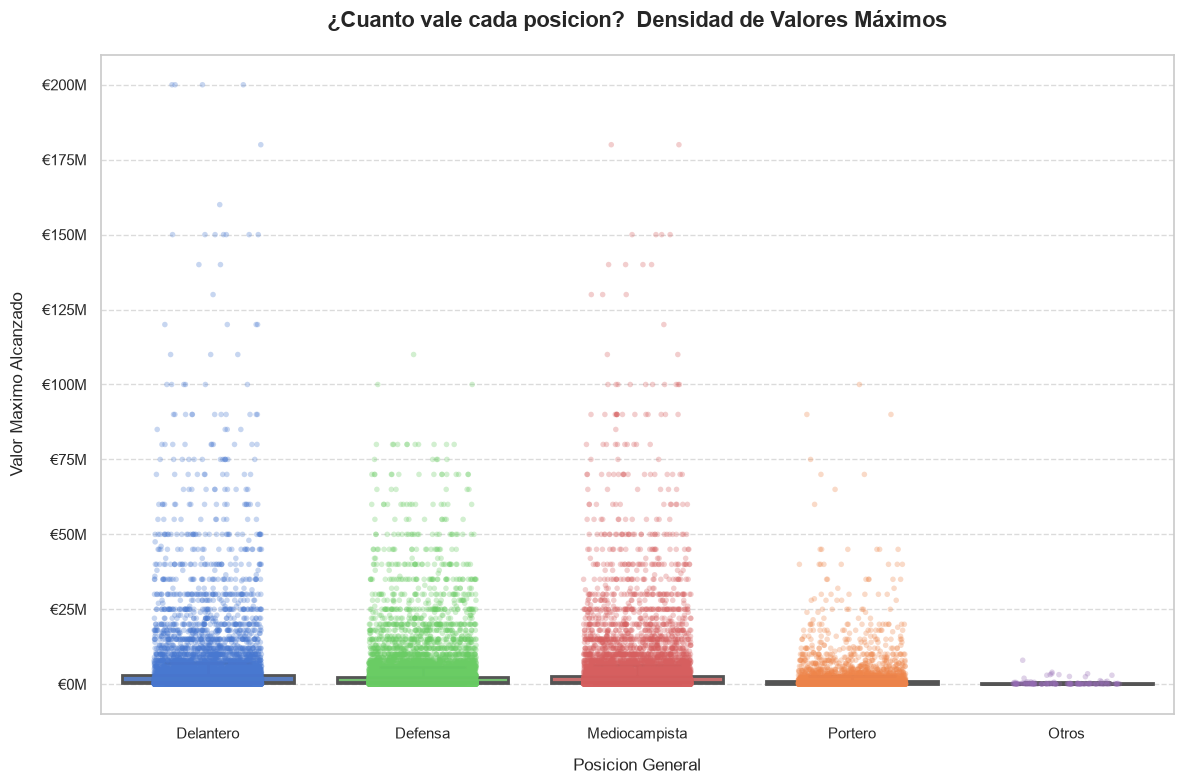

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter


sns.set_theme(style="whitegrid", palette="muted")
fig, ax = plt.subplots(figsize=(12, 8))


orden_posiciones = df_nuevo1.groupby('posicion_general')['valor_maximo'].median().sort_values(ascending=False).index


sns.boxplot(
    data=df_nuevo1, 
    x='posicion_general', 
    y='valor_maximo', 
    order=orden_posiciones,
    hue='posicion_general',
    showfliers=False,     
    linewidth=2,
    ax=ax,
    legend=False
)


sns.stripplot(
    data=df_nuevo1,
    x='posicion_general',
    y='valor_maximo',
    order=orden_posiciones,
    hue='posicion_general',
    jitter=0.25,           
    size=4,
    alpha=0.3,           
    ax=ax,
    legend=False
)


def formato_millones(x, pos):
    return f'€{x * 1e-6:.0f}M'

ax.yaxis.set_major_formatter(FuncFormatter(formato_millones))


plt.title("¿Cuanto vale cada posicion?  Densidad de Valores Máximos", fontsize=16, fontweight='bold', pad=20)
plt.xlabel("Posicion General", fontsize=12, labelpad=12)
plt.ylabel("Valor Maximo Alcanzado", fontsize=12, labelpad=12)


ax.grid(axis='x', linestyle='')
ax.grid(axis='y', linestyle='--', alpha=0.7)


plt.tight_layout()


plt.show()

In [6]:
filtro_elite = (df_nuevo1['valor_maximo'] >= 10_000_000) & (df_nuevo1['impacto_ofensivo'] >= 5)
df_filtrado = df_nuevo1[filtro_elite].copy()


top_gangas = df_filtrado.sort_values(by='eficiencia_por_millon', ascending=False).head(5)


filtro_atacantes = df_filtrado['posicion_general'].isin(['Delantero', 'Mediocampista'])
top_sobrevalorados = df_filtrado[filtro_atacantes].sort_values(by='eficiencia_por_millon', ascending=True).head(5)

def mostrar_top(df_top, titulo):
    print(titulo)
    print("-" * 85)
    for i, row in df_top.iterrows():
        valor_M = f"€{row['valor_maximo'] / 1e6:.1f}M"
        print(f"• {row['name']:<25} | Posición: {row['posicion_general']:<13} | Edad: {row['age']:<2} | Valor Máx: {valor_M:<7} | G+A Totales: {int(row['impacto_ofensivo'])}")


mostrar_top(top_gangas, "TOP 5 JUGADORES 'GANGA'")
mostrar_top(top_sobrevalorados, "TOP 5 JUGADORES 'SOBREVALORADOS'")

TOP 5 JUGADORES 'GANGA'
-------------------------------------------------------------------------------------
• Luuk de Jong              | Posición: Delantero     | Edad: 36 | Valor Máx: €13.0M  | G+A Totales: 330
• James Tavernier           | Posición: Defensa       | Edad: 35 | Valor Máx: €10.0M  | G+A Totales: 218
• Konstantinos Fortounis    | Posición: Mediocampista | Edad: 34 | Valor Máx: €10.0M  | G+A Totales: 182
• Steven Berghuis           | Posición: Delantero     | Edad: 35 | Valor Máx: €15.0M  | G+A Totales: 268
• Edin Visca                | Posición: Delantero     | Edad: 36 | Valor Máx: €13.0M  | G+A Totales: 229
TOP 5 JUGADORES 'SOBREVALORADOS'
-------------------------------------------------------------------------------------
• Carlos Baleba             | Posición: Mediocampista | Edad: 22 | Valor Máx: €60.0M  | G+A Totales: 7
• Kalvin Phillips           | Posición: Mediocampista | Edad: 31 | Valor Máx: €50.0M  | G+A Totales: 6
• Kaishu Sano               | Posición: 